In [5]:
!pip install -q medmnist

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import random, json, os, time, copy
import matplotlib.pyplot as plt, pandas as pd
from scipy.ndimage import gaussian_filter
from medmnist import BloodMNIST
from google.colab import drive

drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/fl_bloodmnist_cpu'
os.makedirs(OUT, exist_ok=True)
device = 'cpu'
torch.set_num_threads(os.cpu_count())
print('Using', device, 'with', os.cpu_count(), 'threads')

Mounted at /content/drive
Using cpu with 2 threads


In [6]:
tr = BloodMNIST(split='train', download=True, size=28)
va = BloodMNIST(split='val',   download=True, size=28)
te = BloodMNIST(split='test',  download=True, size=28)
Xtr, ytr = tr.imgs, tr.labels.squeeze()
Xva, yva = va.imgs, va.labels.squeeze()
Xte, yte = te.imgs, te.labels.squeeze()
print(Xtr.shape, Xva.shape, Xte.shape)

K = 5
def split_stratified(y, K, rng):
    parts = [[] for _ in range(K)]
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        for i, chunk in enumerate(np.array_split(idx, K)):
            parts[i].extend(chunk)
    return [np.array(p) for p in parts]

rng = np.random.default_rng(0)
tr_parts = split_stratified(ytr, K, rng)
te_parts = split_stratified(yte, K, rng)

100%|██████████| 35.5M/35.5M [00:31<00:00, 1.14MB/s]


(11959, 28, 28, 3) (1712, 28, 28, 3) (3421, 28, 28, 3)


In [7]:
HOSPITALS = {
    0: dict(gain=(1.00, 1.00, 1.00), bright=1.0, blur=0.0),   # reference
    1: dict(gain=(1.25, 1.00, 0.75), bright=1.0, blur=0.0),   # warm
    2: dict(gain=(0.80, 0.95, 1.25), bright=0.9, blur=0.0),   # cool
    3: dict(gain=(1.10, 0.85, 1.10), bright=0.7, blur=0.25),  # magenta, dark
    4: dict(gain=(0.90, 1.15, 0.90), bright=1.1, blur=0.45),  # green, blurry
}
UNSEEN = dict(gain=(1.30, 0.90, 0.70), bright=0.8, blur=0.3)  # new hospital

def shift(X, gain, bright, blur):
    X = X.astype(np.float32) / 255.
    X = X * np.array(gain, dtype=np.float32) * bright
    if blur > 0:
        X = gaussian_filter(X, sigma=(0, blur, blur, 0))
    return np.clip(X, 0, 1)

def gray_world(X):
    m = X.mean(axis=(1, 2), keepdims=True)
    g = m.mean(axis=3, keepdims=True)
    return np.clip(X * g / (m + 1e-6), 0, 1)

def to_t(X):
    return torch.from_numpy((X - 0.5) / 0.5).permute(0, 3, 1, 2).contiguous()

def build(norm):
    clients = []
    for i in range(K):
        a = shift(Xtr[tr_parts[i]], **HOSPITALS[i])
        b = shift(Xte[te_parts[i]], **HOSPITALS[i])
        if norm: a, b = gray_world(a), gray_world(b)
        clients.append(dict(Xtr=to_t(a), ytr=torch.tensor(ytr[tr_parts[i]]).long(),
                            Xte=to_t(b), yte=torch.tensor(yte[te_parts[i]]).long()))
    h = shift(Xva, **UNSEEN)
    if norm: h = gray_world(h)
    return clients, (to_t(h), torch.tensor(yva).long())

DATA = {False: build(False), True: build(True)}

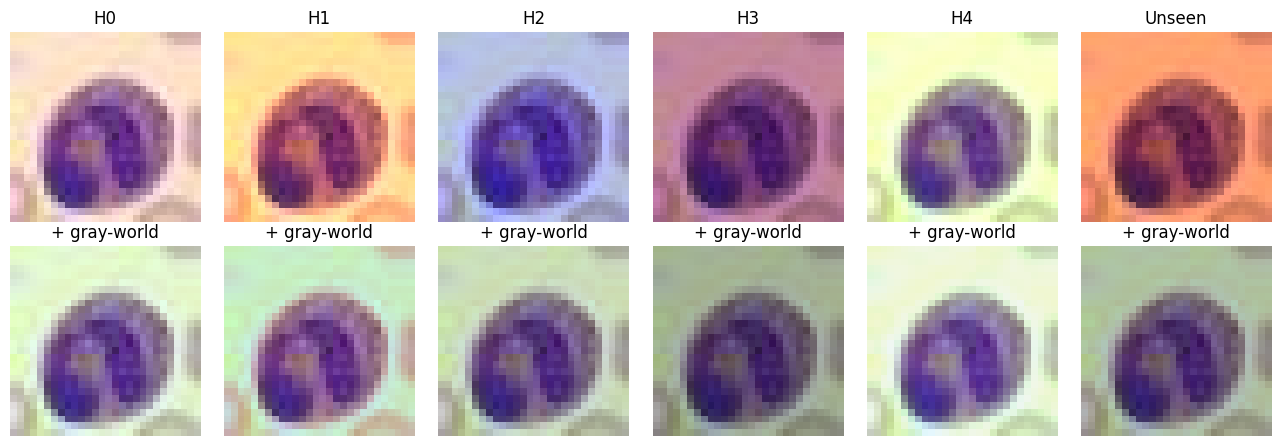

In [8]:
idx = 7
cfgs = list(HOSPITALS.values()) + [UNSEEN]
names = [f'H{i}' for i in range(K)] + ['Unseen']
fig, ax = plt.subplots(2, 6, figsize=(13, 4.5))
for j, cfg in enumerate(cfgs):
    img = shift(Xte[idx:idx+1], **cfg)
    ax[0, j].imshow(img[0]); ax[0, j].set_title(names[j])
    ax[1, j].imshow(gray_world(img)[0]); ax[1, j].set_title('+ gray-world')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/hospitals.png', dpi=200); plt.show()

In [9]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def make_model():
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False),
                             nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 8)).to(device)

BN_KEYS = set()
for name, mod in make_model().named_modules():
    if isinstance(mod, nn.BatchNorm2d):
        BN_KEYS |= {f'{name}.{k}' for k in mod.state_dict()}

def is_bn(k):
    return k in BN_KEYS

def make_loader(X, y, seed):
    g = torch.Generator().manual_seed(seed)
    return torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y),
                                       batch_size=64, shuffle=True, generator=g)

def local_train(model, loader, lr=0.01):
    model.train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    for x, y in loader:
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True)
        loss.backward(); opt.step()

@torch.no_grad()
def evaluate(model, X, y):
    model.eval(); correct = 0
    for i in range(0, len(X), 512):
        correct += (model(X[i:i+512]).argmax(1) == y[i:i+512]).sum().item()
    return correct / len(X)

@torch.no_grad()
def recalibrate_bn(model, X):
    # re-estimate batch-norm statistics from unlabeled images (no labels used)
    m = copy.deepcopy(model)
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats(); mod.momentum = None
    m.train()
    for i in range(0, len(X), 256):
        m(X[i:i+256])
    m.eval()
    return m

def average(states, w):
    avg = {}
    for k in states[0]:
        if 'num_batches_tracked' in k:
            avg[k] = states[0][k]; continue
        avg[k] = sum(wi * s[k].float() for s, wi in zip(states, w)).to(states[0][k].dtype)
    return avg

def run(method, seed, norm, rounds=15):
    set_seed(seed)
    clients, (Xu, yu) = DATA[norm]
    loaders = [make_loader(c['Xtr'], c['ytr'], seed) for c in clients]
    n = np.array([len(c['ytr']) for c in clients]); w = n / n.sum()
    gm, worker = make_model(), make_model()
    bn_local = [{k: v.clone() for k, v in gm.state_dict().items() if is_bn(k)} for _ in range(K)]

    for r in range(rounds):
        states = []
        for i in range(K):
            worker.load_state_dict(gm.state_dict())
            if method == 'fedbn':
                worker.load_state_dict(bn_local[i], strict=False)
            local_train(worker, loaders[i])
            st = {k: v.detach().clone() for k, v in worker.state_dict().items()}
            states.append(st)
            if method == 'fedbn':
                bn_local[i] = {k: v for k, v in st.items() if is_bn(k)}
        gm.load_state_dict(average(states, w))

    per, per_recal = [], []
    for i, c in enumerate(clients):
        worker.load_state_dict(gm.state_dict())
        if method == 'fedbn':
            worker.load_state_dict(bn_local[i], strict=False)
        per.append(evaluate(worker, c['Xte'], c['yte']))
        per_recal.append(evaluate(recalibrate_bn(gm, c['Xtr']), c['Xte'], c['yte']))
    return dict(method=method, norm=norm, seed=seed,
                per_client=per, per_client_recal=per_recal,
                mean=float(np.mean(per)), worst=float(np.min(per)),
                unseen=evaluate(gm, Xu, yu),
                mean_recal=float(np.mean(per_recal)), worst_recal=float(np.min(per_recal)),
                unseen_recal=evaluate(recalibrate_bn(gm, Xu), Xu, yu))

In [10]:
t = time.time()
print(run('fedavg', 0, False, rounds=2), f'{time.time()-t:.0f}s')

{'method': 'fedavg', 'norm': False, 'seed': 0, 'per_client': [0.7641921397379913, 0.18248175182481752, 0.24671532846715327, 0.33771929824561403, 0.23970588235294119], 'per_client_recal': [0.8107714701601164, 0.7868613138686131, 0.7868613138686131, 0.8172514619883041, 0.8191176470588235], 'mean': 0.35416288012570346, 'worst': 0.18248175182481752, 'unseen': 0.1822429906542056, 'mean_recal': 0.8041726413888941, 'worst_recal': 0.7868613138686131, 'unseen_recal': 0.7879672897196262} 83s


In [11]:
CONFIGS = [('fedavg', False), ('fedavg', True), ('fedbn', False), ('fedbn', True)]
SEEDS = [0, 1]
path = f'{OUT}/results_cpu.json'
results = json.load(open(path)) if os.path.exists(path) else []
done = {(r['method'], r['norm'], r['seed']) for r in results}

for seed in SEEDS:
    for method, norm in CONFIGS:
        if (method, norm, seed) in done: continue
        t = time.time(); r = run(method, seed, norm)
        results.append(r); json.dump(results, open(path, 'w'))
        print(f"{method:6s} GW={norm!s:5s} seed={seed} | mean={r['mean']:.3f} "
              f"worst={r['worst']:.3f} unseen={r['unseen']:.3f} | recal: "
              f"mean={r['mean_recal']:.3f} worst={r['worst_recal']:.3f} "
              f"unseen={r['unseen_recal']:.3f} ({time.time()-t:.0f}s)")

fedavg GW=False seed=0 | mean=0.388 worst=0.182 unseen=0.182 | recal: mean=0.883 worst=0.873 unseen=0.865 (405s)
fedavg GW=True  seed=0 | mean=0.600 worst=0.270 unseen=0.552 | recal: mean=0.892 worst=0.851 unseen=0.922 (402s)
fedbn  GW=False seed=0 | mean=0.688 worst=0.424 unseen=0.182 | recal: mean=0.888 worst=0.880 unseen=0.867 (405s)
fedbn  GW=True  seed=0 | mean=0.798 worst=0.760 unseen=0.585 | recal: mean=0.893 worst=0.855 unseen=0.925 (406s)
fedavg GW=False seed=1 | mean=0.424 worst=0.184 unseen=0.182 | recal: mean=0.877 worst=0.863 unseen=0.872 (402s)
fedavg GW=True  seed=1 | mean=0.638 worst=0.341 unseen=0.635 | recal: mean=0.900 worst=0.855 unseen=0.922 (406s)
fedbn  GW=False seed=1 | mean=0.769 worst=0.556 unseen=0.182 | recal: mean=0.875 worst=0.860 unseen=0.873 (406s)
fedbn  GW=True  seed=1 | mean=0.799 worst=0.765 unseen=0.688 | recal: mean=0.891 worst=0.854 unseen=0.919 (400s)


              mean  worst  unseen  mean_recal  worst_recal  unseen_recal
name                                                                    
fedavg       0.406  0.183   0.182       0.880        0.868         0.869
fedavg + GW  0.619  0.306   0.593       0.896        0.853         0.922
fedbn        0.729  0.490   0.182       0.882        0.870         0.870
fedbn + GW   0.798  0.763   0.636       0.892        0.855         0.922


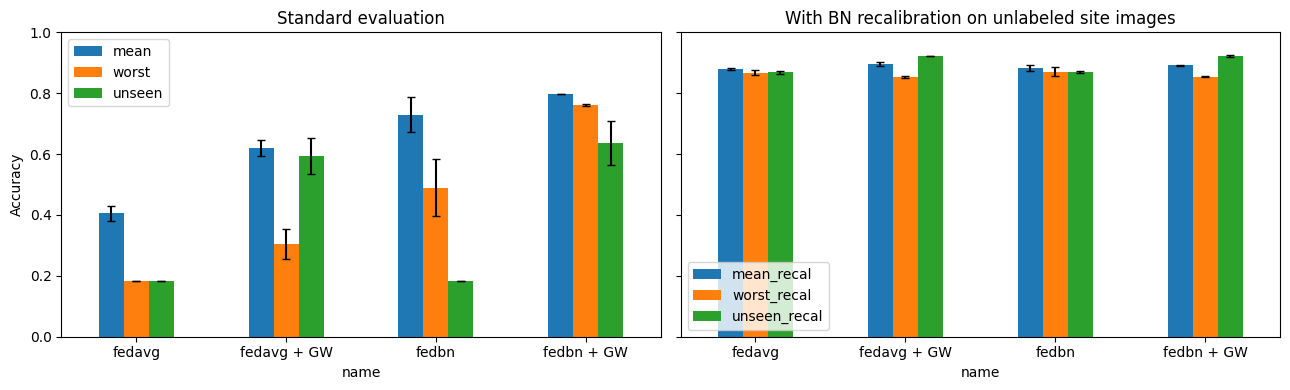

In [12]:
df = pd.DataFrame(results)
df['name'] = df['method'] + df['norm'].map({True: ' + GW', False: ''})
order = ['fedavg', 'fedavg + GW', 'fedbn', 'fedbn + GW']
cols = ['mean', 'worst', 'unseen', 'mean_recal', 'worst_recal', 'unseen_recal']
m = df.groupby('name')[cols].mean().loc[order]
s = df.groupby('name')[cols].std().loc[order]
print(m.round(3)); m.round(3).to_csv(f'{OUT}/summary.csv')

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
m[['mean', 'worst', 'unseen']].plot.bar(yerr=s[['mean', 'worst', 'unseen']],
                                        ax=ax[0], capsize=3, rot=0)
ax[0].set_title('Standard evaluation')
m[['mean_recal', 'worst_recal', 'unseen_recal']].plot.bar(
    yerr=s[['mean_recal', 'worst_recal', 'unseen_recal']], ax=ax[1], capsize=3, rot=0)
ax[1].set_title('With BN recalibration on unlabeled site images')
ax[0].set_ylabel('Accuracy'); ax[0].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f'{OUT}/main_result.png', dpi=200); plt.show()